# Exact, linear, quadratic, and cubic source evolution

A variable irradiating source heats different parts of a disk at different
delays. We can evaluate the nonlinear disk brightness at every epoch, or
expand its response about the mean irradiation. This notebook compares all
four choices for the **same Q2237+0305 image-B-like realization**.

We generate ten years of daily, six-band photometry with 25-day microlensing
maps. First we compare six monochromatic LSST effective wavelengths. Then
we time the full spectral workflow with 32 continuum wavelengths, empirical
spectral components, integrated LSST bands, and 1000-point output spectra.
All calculations and plots are made here.
No saved simulations are loaded. The default example uses a 1024-square disk
and CUDA/Triton. First calls can take substantially longer while compiling.
A smaller CPU configuration is included for checking the API, not GPU timing.

## What is being approximated?

Write the dimensionless irradiation driver as $X(t)=\bar X+\delta X(t)$.
For a disk element at position $\boldsymbol{x}$, the thermal model has

$$T^4(\boldsymbol{x},t)=T_{\rm visc}^4(\boldsymbol{x})
  +Q(\boldsymbol{x})X[t-\tau(\boldsymbol{x})].$$

Here $Q$ is the heating contribution per unit driver amplitude and $\tau$
includes the disk response delay in the observer frame. The Kerr transfer
and redshift are included in the observed brightness $S_b$ in band $b$.
At fixed disk geometry, expand that brightness about $\bar X$:

$$S_b(\boldsymbol{x},t)\simeq S_{b,0}(\boldsymbol{x})
  +S_{b,1}(\boldsymbol{x})\delta X(t-\tau)
  +\tfrac12 S_{b,2}(\boldsymbol{x})[\delta X(t-\tau)]^2,$$

where $S_{b,n}=\left.\partial^n S_b/\partial X^n\right|_{\bar X}$.

- `exact` evaluates the nonlinear temperature and Planck brightness. It is
  the default and our numerical reference, not a continuum-resolution truth.
- `linear_response` keeps the mean and first derivative.
- `quadratic_response` also keeps the second derivative, including its sign.
- `cubic_response` adds the third derivative.

Microlensing weights each element by $\mu(\boldsymbol{x},t)$. With pixel
areas absorbed into $S$, define the **unnormalized** response

$$\psi_{b,n}(\tau;t)=\sum_p\mu_p(t)S_{b,n,p}\,
  \delta_{\rm D}(\tau-\tau_p).$$

Then the quadratic flux is

$$F_b(t)\simeq F_{b,0}(t)+\int\psi_{b,1}(\tau;t)\delta X(t-\tau)\,d\tau
   +\tfrac12\int\psi_{b,2}(\tau;t)[\delta X(t-\tau)]^2\,d\tau.$$

This is a convolution with the **squared driver fluctuation**, not the square
of the linear light curve. Cubic evolution adds

$$F_b^{(3)}(t)=F_b^{(2)}(t)+\tfrac16\int\psi_{b,3}(\tau;t)
[\delta X(t-\tau)]^3\,d\tau.$$

The three derivatives share one temperature and Planck evaluation. The cubic
driver integrator shares knot searches and interval moments across all
powers. Signed response weights are split into positive and negative parts
before CDF reconstruction. The projected coefficients are then combined so
all three orders contribute through one matrix multiplication. No additional
microlensing maps are generated for the extra order.

The mean term and responses are calculated at
each map epoch and interpolated to the daily photometry times. The response
modes use the package's default mass-conserving CDF/PCHIP reconstruction with
automatic native delay spacing. Exact evolution evaluates the delayed driver
at the source pixels instead. Consequently, differences from exact include
both Taylor truncation and numerical response reconstruction. All four share
the same finite source grid, map cadence, and lens calculation.

In [1]:
from pathlib import Path
import json
import platform
from time import perf_counter
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import microcaustics as mc

torch.set_num_threads(4)
GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
DURATION = 3650 if GPU else 100
PIXELS = 1024 if GPU else 64
RAYS = 10_000_000 if GPU else 4096
REPEATS = 5
bands = dict(zip("ugrizy", (3671., 4827., 6223., 7546., 8691., 9712.), strict=True))
modes = ("exact", "linear_response", "quadratic_response", "cubic_response")
labels = ("Exact", "Linear", "Quadratic", "Cubic")
output = Path.cwd() / "source_evolution_comparison_output"
output.mkdir(exist_ok=True)
print("Package:", mc.__file__)
print("Python:", platform.python_version(), "PyTorch:", torch.__version__)
print("Device:", torch.cuda.get_device_name() if GPU else "CPU")
print(f"Disk: {PIXELS} x {PIXELS}; rays: {RAYS:,}; duration: {DURATION} days")

Package: C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\__init__.py
Python: 3.11.15 PyTorch: 2.12.1+cu130
Device: NVIDIA GeForce RTX 5070 Ti
Disk: 1024 x 1024; rays: 10,000,000; duration: 3650 days


## One physical setup for all four modes

The daily driver has mean one, standard deviation 0.3, a 200-day PSD break,
and low/high-frequency slopes 1 and 3. Its fixed history and fivefold FFT
padding are unchanged between calls. Separate fixed seeds specify the
driver and stellar realization. Source construction is timed separately.

In [2]:
driver = mc.broken_power_law_driving_signal(
    cadence_days=1., max_duration_days=3650., history_days=1000.,
    break_timescale_days=200., alpha_L=1., alpha_R=3.,
    mean_amplitude=1., standard_deviation=0.3, padding_factor=5, seed=0,
)
source = mc.KerrDiskModel(
    black_hole_mass_solar=10**9.08, eddington_ratio=0.34,
    spin=0.74, inclination_deg=10., position_angle_deg=0.,
    bands_angstrom=bands, lamp_fraction=0.1,
    corona_height_above_isco_rg=20., driving_signal=driver,
    source_grid_shape=PIXELS, enclosed_flux_fraction=0.999, source_margin=1.05,
    compute_emission_azimuth=False,
)
system = mc.MicrolensingSystem(
    lens_redshift=0.0395, source_redshift=1.695,
    macro=mc.MacroLens(convergence=0.391, shear=0.391,
                      shear_angle_deg=141.73, smooth_matter_fraction=0.),
    source=source,
    stellar_population=mc.StellarPopulation.salpeter(
        mean_mass_solar=0.3, mass_ratio=100.,
        kinematics=mc.SkyProjectedKinematics(
            ra_deg=340.126125, dec_deg=3.358611,
            stellar_dispersion_km_s=170.,
            peculiar_velocity_dispersion_km_s=235.,
            include_cmb_dipole=True, seed=23,
        ),
    ),
    duration_days=DURATION, light_loss=0.01, safety_scale=1.5, seed=23,
    runtime=mc.RuntimeConfig(
        device=DEVICE, backend="triton" if GPU else "torch_eager",
        strict_backend=True, memory_fraction=0.8, response_reconstruction="cdf",
    ),
)

def synchronize():
    if GPU:
        torch.cuda.synchronize()

synchronize()
start = perf_counter()
realization = system.realize()
synchronize()
setup_seconds = perf_counter() - start
print(f"Physical realization and source setup: {setup_seconds:.2f} s")
print(f"Stars: {len(realization.stars)}")

options = dict(
    duration_days=DURATION, map_cadence_days=25., source_cadence_days=1.,
    rays=RAYS, temporal_batch_size=25 if GPU else 2, scout_refresh_frames=10,
    apply_driving_signal=True, include_labels=False,
)

@torch.inference_mode()
def evaluate(mode):
    return system.light_curve(source_evolution=mode, **options)

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\primary.py:223: CompilationWarning: Compilation event 1: preparing a new torch.compile specialization for primary Kerr ray tracing on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  calculation, execution = _primary_calculation(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\coordinates.py:1164: CompilationWarning: Compilation event 2: preparing a new torch.compile specialization for Kerr observer coordinates on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  solver, execution = _coordinate_solver(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\lamppost.py:637: CompilationWarning: Compilation event 3: preparing a new torch.compile specialization for axis-lamppost ray tracing on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  rays = trace_axis_lamppost(


Physical realization and source setup: 17.46 s
Stars: 3810


## Timing and accuracy

We first run each mode once, then time five more complete light-curve calls
in rotating order, synchronizing the GPU before and after each call. Each
call regenerates the maps and calculates the fluxes. Compatible source
products and compiled kernels can be reused. Timings exclude the initial
physical realization, plotting, disk writes, and caustic labels. First-call
times may reuse a disk compiler cache and are **not pure compilation times**.

Errors are computed from $\Delta m=-2.5\log_{10}(F/F_{m exact})$, without
subtracting a mean or fitting an amplitude. The RMSE below pools all epochs
and bands. The per-band plot also shows the maximum absolute error.

In [3]:
curves, first_seconds = {}, {}
for mode in modes:
    synchronize()
    start = perf_counter()
    curves[mode] = evaluate(mode)
    synchronize()
    first_seconds[mode] = perf_counter() - start
    print(f"{mode}: first call {first_seconds[mode]:.3f} s", flush=True)

seconds = {mode: [] for mode in modes}
for repeat in range(REPEATS):
    for mode in modes[repeat % len(modes):] + modes[:repeat % len(modes)]:
        synchronize()
        start = perf_counter()
        result = evaluate(mode)
        synchronize()
        seconds[mode].append(perf_counter() - start)
        torch.testing.assert_close(result.flux, curves[mode].flux)
    print(f"Finished warmed repeat {repeat + 1}/{REPEATS}", flush=True)

reference = curves["exact"].flux.detach().cpu().numpy()
times = curves["exact"].times_days.detach().cpu().numpy()
residuals, records = {}, []
warmed_exact = np.median(seconds["exact"])
for mode, label in zip(modes, labels):
    curve = curves[mode]
    torch.testing.assert_close(curve.times_days, curves["exact"].times_days)
    flux = curve.flux.detach().cpu().numpy()
    assert flux.shape == (DURATION + 1, len(bands))
    assert np.isfinite(flux).all() and (flux > 0).all()
    residuals[mode] = -2500. * np.log10(flux / reference)
    error = residuals[mode]
    records.append(dict(
        mode=label, first_seconds=first_seconds[mode],
        warmed_seconds=float(np.median(seconds[mode])),
        speedup=float(warmed_exact / np.median(seconds[mode])),
        rmse_mmag=float(np.sqrt(np.mean(error**2))),
        max_abs_mmag=float(np.max(np.abs(error))),
    ))
table = "| Mode | First call [s] | Warmed median [s] | Speedup | RMSE [mmag] | Max [mmag] |\n"
table += "|---|---:|---:|---:|---:|---:|\n"
for row in records:
    table += (f"| {row['mode']} | {row['first_seconds']:.3f} | "
              f"{row['warmed_seconds']:.3f} | {row['speedup']:.2f} | "
              f"{row['rmse_mmag']:.3g} | {row['max_abs_mmag']:.3g} |\n")
display(Markdown(table))
(output / "summary.json").write_text(json.dumps(dict(
    records=records, warmed_samples_seconds=seconds, setup_seconds=setup_seconds,
    pixels=PIXELS, rays=RAYS, duration_days=DURATION,
    device=torch.cuda.get_device_name() if GPU else "CPU",
    torch_version=str(torch.__version__),
    per_band_rmse_mmag={mode: np.sqrt(np.mean(error**2, axis=0)).tolist()
                       for mode, error in residuals.items()},
), indent=2))

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 4: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:940: CompilationWarning: Compilation event 5: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1397: CompilationWarning: Compilation event 6: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\reprocessing.py:585: CompilationWarning: Compilation event 7: preparing a new torch.compile specialization for retarded thermal driving on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  temperature4, _ = run_tensor_kernel(
C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:229: CompilationWarning: Compilation event 8: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_ther

exact: first call 4.625 s


...

Finished warmed repeat 3/5


Finished warmed repeat 4/5


Finished warmed repeat 5/5


| Mode | First call [s] | Warmed median [s] | Speedup | RMSE [mmag] | Max [mmag] |
|---|---:|---:|---:|---:|---:|
| Exact | 4.625 | 1.156 | 1.00 | 0 | 0 |
| Linear | 13.394 | 0.923 | 1.25 | 2.58 | 15.2 |
| Quadratic | 11.031 | 0.966 | 1.20 | 0.247 | 2.01 |
| Cubic | 11.779 | 0.981 | 1.18 | 0.0355 | 0.339 |


2476

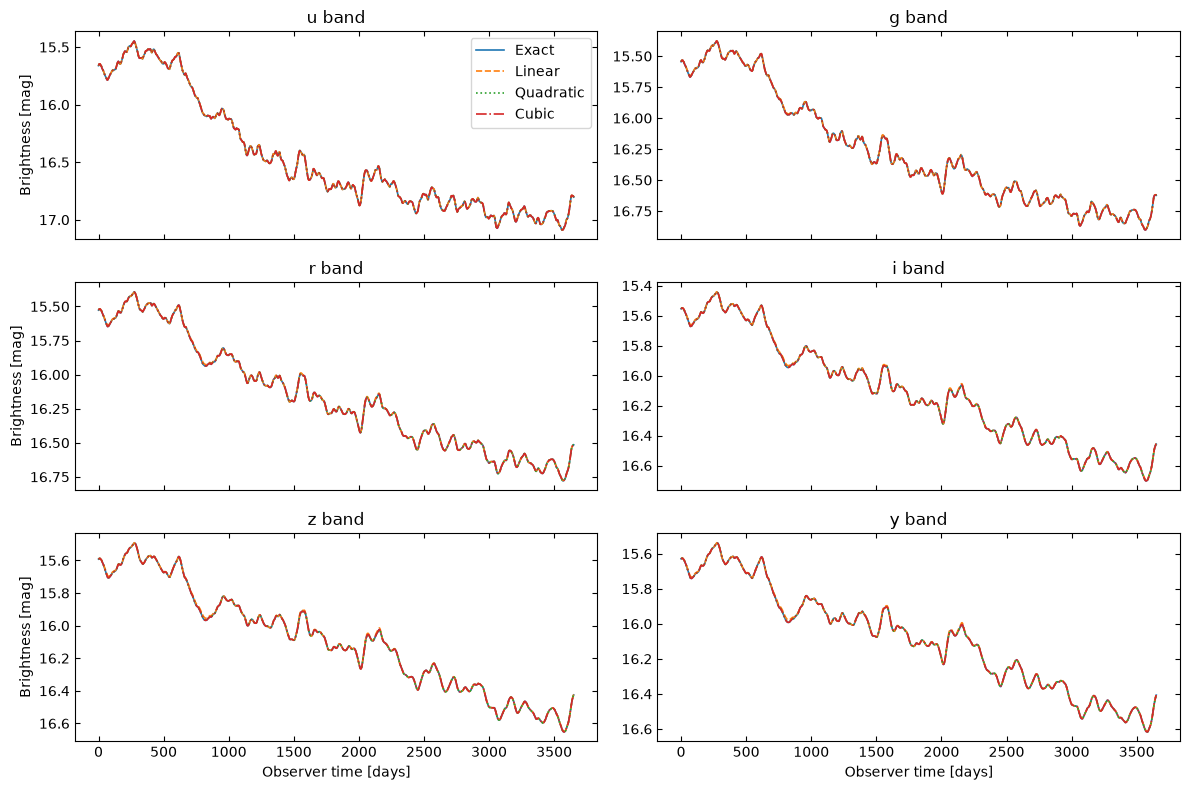

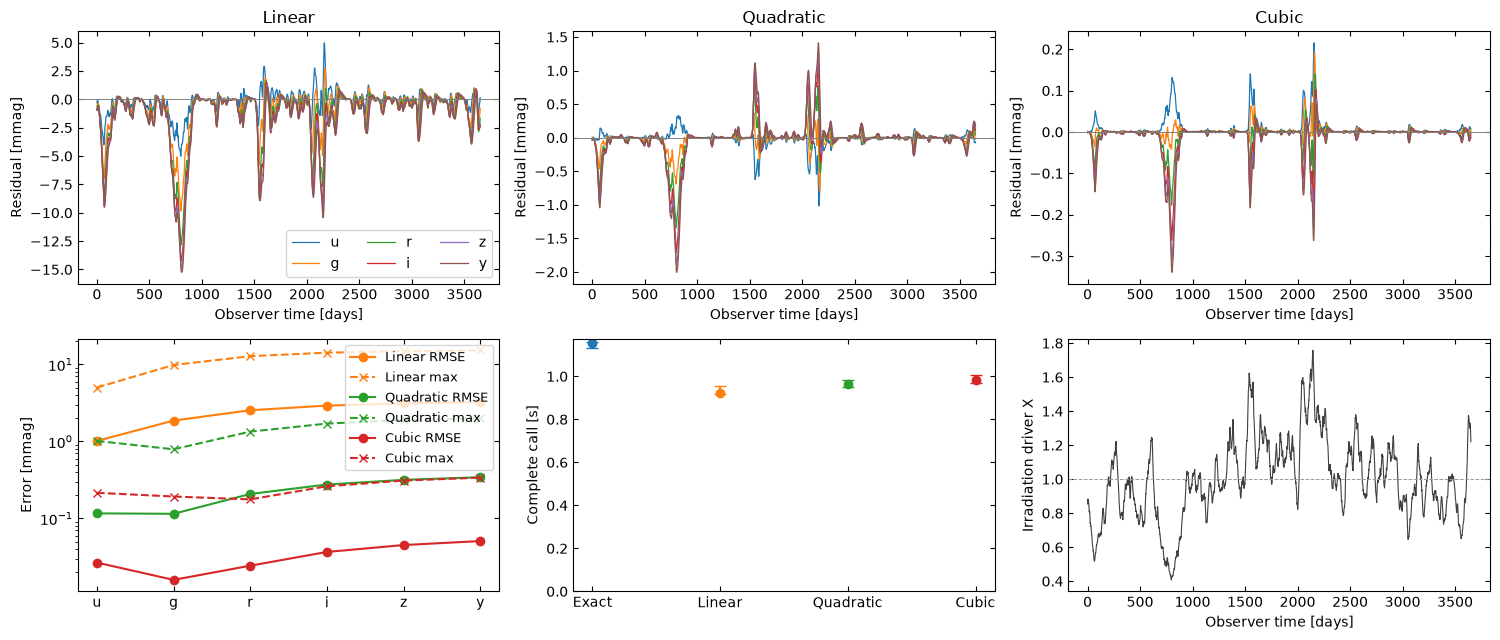

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
styles = ("-", "--", ":", "-.")
for b, (band, ax) in enumerate(zip(bands, axes.flat)):
    for mode, label, style in zip(modes, labels, styles):
        magnitude = curves[mode].magnitude.detach().cpu().numpy()[:, b]
        ax.plot(times, magnitude, style, label=label, linewidth=1.2)
    ax.set_title(f"{band} band")
    ax.invert_yaxis()
    ax.tick_params(direction="in", top=True, right=True)
axes[0, 0].legend(frameon=True)
for ax in axes[:, 0]:
    ax.set_ylabel("Brightness [mag]")
for ax in axes[-1]:
    ax.set_xlabel("Observer time [days]")
fig.tight_layout()
fig.savefig(output / "light_curves.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, mode, title in zip(axes[0], modes[1:], labels[1:]):
    for b, band in enumerate(bands):
        ax.plot(times, residuals[mode][:, b], label=band, linewidth=0.9)
    ax.axhline(0, color="0.5", linewidth=0.7)
    ax.set(title=title, xlabel="Observer time [days]", ylabel="Residual [mmag]")
axes[0, 0].legend(ncol=3, frameon=True)
x = np.arange(len(bands))
for mode, label, color in zip(modes[1:], labels[1:], ("C1", "C2", "C3")):
    error = residuals[mode]
    axes[1, 0].plot(x, np.sqrt(np.mean(error**2, axis=0)), "o-", color=color, label=f"{label} RMSE")
    axes[1, 0].plot(x, np.max(np.abs(error), axis=0), "x--", color=color, label=f"{label} max")
axes[1, 0].set(xticks=x, xticklabels=list(bands), ylabel="Error [mmag]", yscale="log")
axes[1, 0].legend(frameon=True, fontsize=9)
for j, mode in enumerate(modes):
    values = np.array(seconds[mode])
    median = np.median(values)
    axes[1, 1].errorbar(j, median, yerr=[[median - values.min()], [values.max() - median]],
                       fmt="o", capsize=4, color=f"C{j}")
axes[1, 1].set(xticks=range(len(modes)), xticklabels=labels, ylabel="Complete call [s]", ylim=(0, None))
driving = driver.amplitudes(torch.tensor(times), bands=1, dtype=torch.float32, device="cpu")
axes[1, 2].plot(times, driving[:, 0].numpy(), color="0.25", linewidth=0.8)
axes[1, 2].axhline(1, color="0.6", linestyle="--", linewidth=0.7)
axes[1, 2].set(xlabel="Observer time [days]", ylabel="Irradiation driver X")
for ax in axes.flat:
    ax.tick_params(direction="in", top=True, right=True)
fig.tight_layout()
fig.savefig(output / "accuracy_and_runtime.png", dpi=180, bbox_inches="tight")
plt.show()

## Full spectra and bandpass-integrated light curves

This second benchmark evaluates the disk at 32 log-spaced continuum
wavelengths across the LSST filters. The empirical quasar model adds emission
lines and attenuation, and integrates the resulting spectrum over the six
filter throughputs. Host light is omitted for this local macroimage. Template
normalization can require additional disk wavelengths outside the filters.
We return a 1000-point spectrum from 3250 to 10900 Angstrom at every daily
epoch. These 1000 output samples are interpolated spectral products, **not
1000 separately ray-traced disk images**.

We reuse the already pixelated disk so adding wavelengths does not rebuild
the Kerr transfer or change the source field. The stellar and driver seeds,
map settings, duration, daily cadence, and sampled spectral model are fixed
across all four modes. Timings include map generation, continuum evaluation,
the mean-driver reference needed by the spectral model, spectral processing,
bandpass integration, and creation of the returned spectra. They exclude
initial disk construction, labels, plotting, and file writes. As above, first
calls and five warmed complete calls are reported separately.

In [5]:
spectral_system = system.with_source(realization.source)
spectrum_model = mc.QuasarSpectrumPopulation().sample(seed=42)
spectrum_wavelengths = np.linspace(3250., 10900., 1000)
spectral_options = dict(
    **options, bandpasses="lsst", spectral_model=spectrum_model,
    wavelength_samples=32, wavelength_batch_size=32,
    host_lensing="omit", return_spectrum=True,
    spectrum_wavelengths=spectrum_wavelengths,
)

@torch.inference_mode()
def evaluate_spectrum(mode):
    return spectral_system.light_curve(source_evolution=mode, **spectral_options)

spectral_curves, spectral_first_seconds = {}, {}
for mode in modes:
    synchronize()
    start = perf_counter()
    spectral_curves[mode] = evaluate_spectrum(mode)
    synchronize()
    spectral_first_seconds[mode] = perf_counter() - start
    print(f"Spectrum {mode}: first call {spectral_first_seconds[mode]:.3f} s", flush=True)

spectral_seconds = {mode: [] for mode in modes}
for repeat in range(REPEATS):
    for mode in modes[repeat % len(modes):] + modes[:repeat % len(modes)]:
        synchronize()
        start = perf_counter()
        result = evaluate_spectrum(mode)
        synchronize()
        spectral_seconds[mode].append(perf_counter() - start)
        torch.testing.assert_close(result.flux, spectral_curves[mode].flux)
        torch.testing.assert_close(result.spectrum.total_flux,
                                   spectral_curves[mode].spectrum.total_flux)
    print(f"Finished spectral repeat {repeat + 1}/{REPEATS}", flush=True)

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:234: CompilationWarning: Compilation event 22: preparing a new torch.compile specialization for thermal spectral photometry on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


Spectrum exact: first call 10.379 s


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\_response_cdf.py:521: CompilationWarning: Compilation event 23: preparing a new torch.compile specialization for CDF response projection on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\_response_cdf.py:521: CompilationWarning: Compilation event 24: preparing a new torch.compile specialization for phase-averaged CDF polynomials on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


Spectrum linear_response: first call 9.963 s


...

Finished spectral repeat 1/5


Finished spectral repeat 2/5


Finished spectral repeat 3/5


Finished spectral repeat 4/5


Finished spectral repeat 5/5


The spectral accuracy check measures both the integrated band fluxes and
the returned spectrum relative to the exact spectral calculation. Spectral
fractional RMSE is $\sqrt{\langle[(F_\nu-F_{\nu,\rm exact})/
F_{\nu,\rm exact}]^2\rangle}$ over all epochs and output wavelengths.
We also report the continuum alone so static emission lines cannot hide its
approximation error. This does not test the accuracy of the empirical model
or convergence of the 32-wavelength continuum grid.

| Mode | First [s] | Warmed median [s] | Speedup | Band RMSE [mmag] | Band max [mmag] | Spectrum RMS [%] | Continuum RMS [%] |
|---|---:|---:|---:|---:|---:|---:|---:|
| Exact | 10.379 | 3.587 | 1.00 | 0 | 0 | 0 | 0 |
| Linear | 9.963 | 1.068 | 3.36 | 1.89 | 12.3 | 0.19 | 0.245 |
| Quadratic | 7.701 | 1.153 | 3.11 | 0.181 | 1.61 | 0.0185 | 0.0235 |
| Cubic | 7.760 | 1.170 | 3.07 | 0.0263 | 0.272 | 0.00268 | 0.00338 |


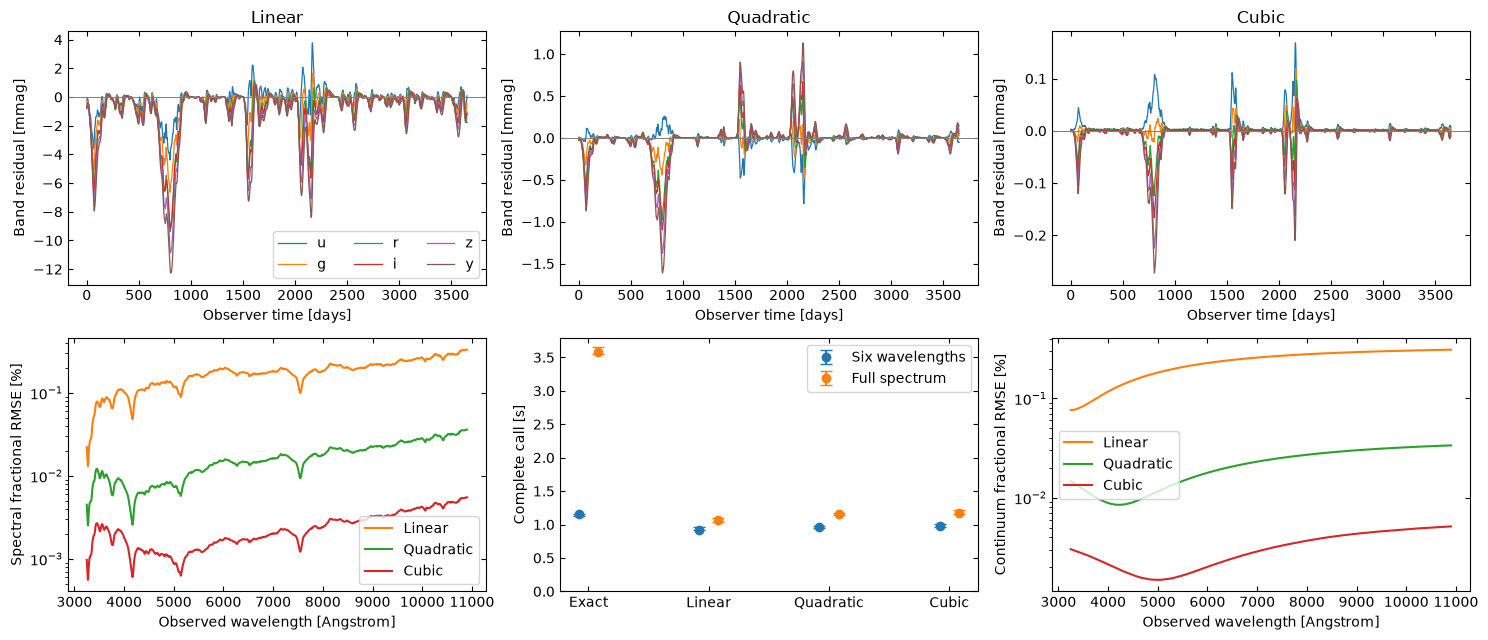

In [6]:
spectral_reference = spectral_curves["exact"]
spectral_residuals, spectral_fractional, spectral_records = {}, {}, []
continuum_fractional = {}
for mode, label in zip(modes, labels):
    curve = spectral_curves[mode]
    torch.testing.assert_close(curve.times_days, spectral_reference.times_days)
    torch.testing.assert_close(curve.spectrum.wavelengths_angstrom,
                               spectral_reference.spectrum.wavelengths_angstrom)
    assert curve.flux.shape == (DURATION + 1, 6)
    assert curve.spectrum.total_flux.shape == (DURATION + 1, 1000)
    for values in (curve.flux, curve.spectrum.total_flux, curve.spectrum.continuum_flux):
        assert torch.isfinite(values).all() and (values > 0).all()
    error = -2500. * torch.log10(curve.flux / spectral_reference.flux)
    fractional = curve.spectrum.total_flux / spectral_reference.spectrum.total_flux - 1.
    continuum_error = curve.spectrum.continuum_flux / spectral_reference.spectrum.continuum_flux - 1.
    spectral_residuals[mode] = error.cpu().numpy()
    spectral_fractional[mode] = fractional.cpu().numpy()
    continuum_fractional[mode] = continuum_error.cpu().numpy()
    spectral_records.append(dict(
        mode=label, first_seconds=spectral_first_seconds[mode],
        warmed_seconds=float(np.median(spectral_seconds[mode])),
        speedup=float(np.median(spectral_seconds["exact"]) / np.median(spectral_seconds[mode])),
        band_rmse_mmag=float(error.square().mean().sqrt()),
        band_max_abs_mmag=float(error.abs().max()),
        spectrum_fractional_rmse=float(fractional.square().mean().sqrt()),
        spectrum_max_abs_fractional=float(fractional.abs().max()),
        continuum_fractional_rmse=float(continuum_error.square().mean().sqrt()),
    ))
table = "| Mode | First [s] | Warmed median [s] | Speedup | Band RMSE [mmag] | Band max [mmag] | Spectrum RMS [%] | Continuum RMS [%] |\n"
table += "|---|---:|---:|---:|---:|---:|---:|---:|\n"
for row in spectral_records:
    table += (f"| {row['mode']} | {row['first_seconds']:.3f} | {row['warmed_seconds']:.3f} | "
              f"{row['speedup']:.2f} | {row['band_rmse_mmag']:.3g} | {row['band_max_abs_mmag']:.3g} | "
              f"{100 * row['spectrum_fractional_rmse']:.3g} | {100 * row['continuum_fractional_rmse']:.3g} |\n")
display(Markdown(table))
(output / "spectrum_summary.json").write_text(json.dumps(dict(
    records=spectral_records, warmed_samples_seconds=spectral_seconds,
    pixels=PIXELS, rays=RAYS, duration_days=DURATION, wavelength_samples=32,
    wavelength_batch_size=32, output_spectrum_samples=1000,
    spectral_model_seed=42, host_lensing="omit",
    device=torch.cuda.get_device_name() if GPU else "CPU",
    torch_version=str(torch.__version__),
), indent=2))

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, mode, label in zip(axes[0], modes[1:], labels[1:]):
    for b, band in enumerate(spectral_reference.band_names):
        ax.plot(times, spectral_residuals[mode][:, b], label=band, linewidth=0.9)
    ax.axhline(0, color="0.5", linewidth=0.7)
    ax.set(title=label, xlabel="Observer time [days]", ylabel="Band residual [mmag]")
axes[0, 0].legend(ncol=3, frameon=True)
for mode, label, color in zip(modes[1:], labels[1:], ("C1", "C2", "C3")):
    error = spectral_fractional[mode]
    axes[1, 0].plot(spectrum_wavelengths, 100 * np.sqrt(np.mean(error**2, axis=0)),
                    color=color, label=label)
    axes[1, 2].plot(spectrum_wavelengths, 100 * np.sqrt(np.mean(continuum_fractional[mode]**2, axis=0)),
                    color=color, label=label)
axes[1, 0].set(xlabel="Observed wavelength [Angstrom]", ylabel="Spectral fractional RMSE [%]", yscale="log")
axes[1, 0].legend(frameon=True)
for j, mode in enumerate(modes):
    for offset, samples, color in ((-0.08, seconds[mode], "C0"), (0.08, spectral_seconds[mode], "C1")):
        median = np.median(samples)
        axes[1, 1].errorbar(j + offset, median,
            yerr=[[median - min(samples)], [max(samples) - median]], fmt="o", capsize=4,
            color=color, label=("Six wavelengths" if offset < 0 else "Full spectrum") if j == 0 else None)
axes[1, 1].set(xticks=range(len(modes)), xticklabels=labels, ylabel="Complete call [s]", ylim=(0, None))
axes[1, 1].legend(frameon=True)
axes[1, 2].set(xlabel="Observed wavelength [Angstrom]", ylabel="Continuum fractional RMSE [%]", yscale="log")
axes[1, 2].legend(frameon=True)
for ax in axes.flat:
    ax.tick_params(direction="in", top=True, right=True)
fig.tight_layout()
fig.savefig(output / "spectrum_accuracy_and_runtime.png", dpi=180, bbox_inches="tight")
plt.show()

## Dependence on driving amplitude

We repeat the full spectral comparison at driver standard deviations 0.1,
0.3, and 0.5, with mean irradiation fixed at one. The driver uses the same
random seed and sampling grid at every amplitude. Its lognormal transform
keeps the heating positive, so changing the standard deviation is not simply
multiplying the existing time series. Within each amplitude, all four modes
use exactly the same driver, disk grid, and microlensing realization.

We reuse the measured 0.3 results above. Each new amplitude receives its own
first call and five warmed repetitions. Errors include both Taylor truncation
and response reconstruction. An error plateau at small amplitude can reflect
the latter, not a failure of the Taylor expansion. Increasing the order is
not guaranteed to improve large excursions.

Finished full-spectrum comparison at sigma_X=0.1


Finished full-spectrum comparison at sigma_X=0.5


| Driver std. | Mode | Warmed [s] | Speedup | Band RMSE [mmag] | Band max [mmag] | Continuum RMS [%] |
|---|---|---:|---:|---:|---:|---:|
| 0.1 | Exact | 3.621 | 1.00 | 0 | 0 | 0 |
| 0.1 | Linear | 1.069 | 3.39 | 0.251 | 1.87 | 0.0319 |
| 0.1 | Quadratic | 1.121 | 3.23 | 0.00933 | 0.103 | 0.00119 |
| 0.1 | Cubic | 1.141 | 3.17 | 0.00138 | 0.00751 | 0.000184 |
| 0.3 | Exact | 3.587 | 1.00 | 0 | 0 | 0 |
| 0.3 | Linear | 1.068 | 3.36 | 1.89 | 12.3 | 0.245 |
| 0.3 | Quadratic | 1.153 | 3.11 | 0.181 | 1.61 | 0.0235 |
| 0.3 | Cubic | 1.170 | 3.07 | 0.0263 | 0.272 | 0.00338 |
| 0.5 | Exact | 3.578 | 1.00 | 0 | 0 | 0 |
| 0.5 | Linear | 1.090 | 3.28 | 4.27 | 23.7 | 0.561 |
| 0.5 | Quadratic | 1.127 | 3.18 | 0.624 | 5.31 | 0.0811 |
| 0.5 | Cubic | 1.169 | 3.06 | 0.147 | 1.75 | 0.0188 |


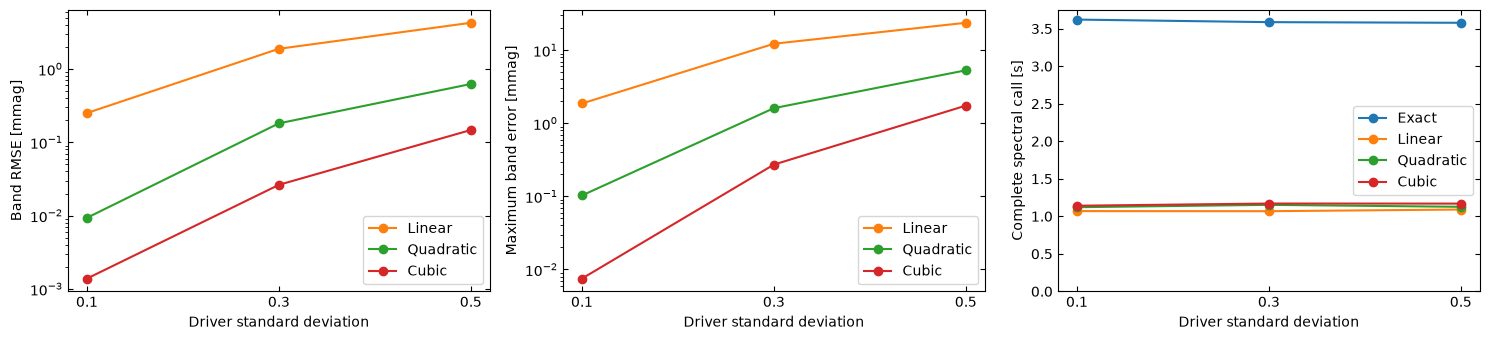

In [7]:
from dataclasses import replace

amplitudes = (0.1, 0.3, 0.5)
amplitude_results = {"0.3": dict(records=spectral_records, samples=spectral_seconds)}
for sigma in (0.1, 0.5):
    amplitude_driver = mc.broken_power_law_driving_signal(
        cadence_days=1., max_duration_days=3650., history_days=1000.,
        break_timescale_days=200., alpha_L=1., alpha_R=3.,
        mean_amplitude=1., standard_deviation=sigma, padding_factor=5, seed=0,
    )
    amplitude_source = replace(realization.source, signal=amplitude_driver)
    amplitude_system = system.with_source(amplitude_source)

    @torch.inference_mode()
    def evaluate_amplitude(mode):
        return amplitude_system.light_curve(source_evolution=mode, **spectral_options)

    amplitude_curves, initial, samples = {}, {}, {mode: [] for mode in modes}
    for mode in modes:
        synchronize()
        start = perf_counter()
        amplitude_curves[mode] = evaluate_amplitude(mode)
        synchronize()
        initial[mode] = perf_counter() - start
    for repeat in range(REPEATS):
        for mode in modes[repeat % len(modes):] + modes[:repeat % len(modes)]:
            synchronize()
            start = perf_counter()
            result = evaluate_amplitude(mode)
            synchronize()
            samples[mode].append(perf_counter() - start)
            torch.testing.assert_close(result.flux, amplitude_curves[mode].flux)
    ref = amplitude_curves["exact"]
    rows = []
    for mode, label in zip(modes, labels):
        curve = amplitude_curves[mode]
        assert torch.isfinite(curve.flux).all() and (curve.flux > 0).all()
        assert torch.isfinite(curve.spectrum.total_flux).all() and (curve.spectrum.total_flux > 0).all()
        error = -2500 * torch.log10(curve.flux / ref.flux)
        fractional = curve.spectrum.total_flux / ref.spectrum.total_flux - 1
        continuum_error = curve.spectrum.continuum_flux / ref.spectrum.continuum_flux - 1
        rows.append(dict(mode=label, first_seconds=initial[mode],
            warmed_seconds=float(np.median(samples[mode])),
            speedup=float(np.median(samples["exact"]) / np.median(samples[mode])),
            band_rmse_mmag=float(error.square().mean().sqrt()),
            band_max_abs_mmag=float(error.abs().max()),
            spectrum_fractional_rmse=float(fractional.square().mean().sqrt()),
            continuum_fractional_rmse=float(continuum_error.square().mean().sqrt())))
    amplitude_results[str(sigma)] = dict(records=rows, samples=samples)
    print(f"Finished full-spectrum comparison at sigma_X={sigma}", flush=True)
(output / "amplitude_summary.json").write_text(json.dumps(amplitude_results, indent=2))
table = "| Driver std. | Mode | Warmed [s] | Speedup | Band RMSE [mmag] | Band max [mmag] | Continuum RMS [%] |\n"
table += "|---|---|---:|---:|---:|---:|---:|\n"
for sigma in amplitudes:
    for row in amplitude_results[str(sigma)]["records"]:
        table += (f"| {sigma} | {row['mode']} | {row['warmed_seconds']:.3f} | {row['speedup']:.2f} | "
                  f"{row['band_rmse_mmag']:.3g} | {row['band_max_abs_mmag']:.3g} | "
                  f"{100 * row['continuum_fractional_rmse']:.3g} |\n")
display(Markdown(table))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for j, label in enumerate(labels):
    rows = [amplitude_results[str(sigma)]["records"][j] for sigma in amplitudes]
    axes[2].plot(amplitudes, [r["warmed_seconds"] for r in rows], "o-", label=label)
    if j:
        axes[0].plot(amplitudes, [r["band_rmse_mmag"] for r in rows], "o-", color=f"C{j}", label=label)
        axes[1].plot(amplitudes, [r["band_max_abs_mmag"] for r in rows], "o-", color=f"C{j}", label=label)
axes[0].set(ylabel="Band RMSE [mmag]", yscale="log")
axes[1].set(ylabel="Maximum band error [mmag]", yscale="log")
axes[2].set(ylabel="Complete spectral call [s]", ylim=(0, None))
for ax in axes:
    ax.set_xlabel("Driver standard deviation")
    ax.set_xticks(amplitudes)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=True)
fig.tight_layout()
fig.savefig(output / "amplitude_accuracy_and_runtime.png", dpi=180, bbox_inches="tight")
plt.show()

## How to use these comparisons

The timing error bars span the fastest and slowest of five warmed calls,
not an uncertainty on physical parameters. The accuracy plots measure the
difference from exact on this same finite grid. They do not test convergence
in ray count, disk resolution, or map cadence.

Quadratic and cubic response retain higher-order terms, but are not guaranteed
to meet an accuracy threshold for every disk or driver. Larger irradiation
fluctuations and different wavelengths can make either expansion inadequate.
Conversely, a small error does not guarantee a useful speedup when map
construction dominates the runtime. Response modes also store spatial
response weights, which can increase memory use.

A much finer driver grid can also force a finer native CDF grid and larger
response arrays. If the response-memory limit is reached, use a shorter
example or a justified delay spacing. Do not change the driver cadence for
just one mode, since that would no longer be a matched comparison.

Keep `exact` when its cost is acceptable. Compare an approximation against
it using the amplitudes, bands, and lag accuracy relevant to your application.
These response modes require a thermal-reprocessing source with a stationary
source trajectory. Stars can still move. They do not approximate stellar
motion or reduce the daily photometry cadence. The microimage
callback currently requires exact evolution and is not used here.